In [1]:
import lenstronomy

import numpy as np
import os
import matplotlib.pyplot as plt

from lenstronomy.LensModel.lens_model import LensModel
from lenstronomy.LightModel.light_model import LightModel



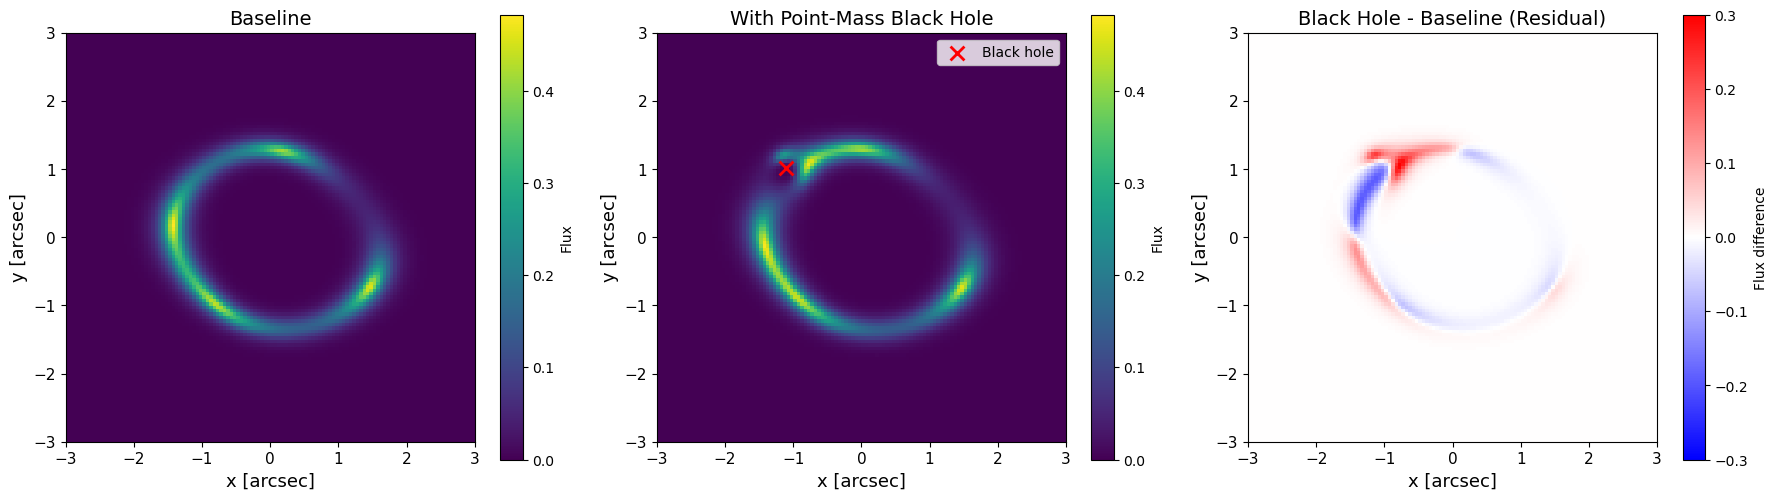

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from lenstronomy.SimulationAPI.sim_api import SimAPI
from lenstronomy.SimulationAPI.ObservationConfig.HST import HST
from lenstronomy.Util.param_util import (phi_q2_ellipticity, shear_polar2cartesian)

from lenstronomy.Cosmo.lens_cosmo import LensCosmo

# Define BH parameters
M_bh = 8362347149.007823
bh_x = -1.111
bh_y = 1.022


# Use HST-like image properties --> this defines how telescope observes the light
kwargs_single_band = {
    "pixel_scale": 0.05,          # arcsec/pixel
    "exposure_time": 524.0,      # seconds
    "magnitude_zero_point": 25.94,
    "read_noise": 5.25,           
    "ccd_gain": 2.0,             
    "sky_brightness": 22.0,   
    "num_exposures": 4,
    "seeing": 0.10,               # PSF FWHM, arcsec
    "psf_type": "GAUSSIAN"}
# number of pixels on each side of image
numpix = 120

# redshift of lens and source
z_lens = 0.222
z_source = 0.609

# Objects in model
kwargs_model = {
    "lens_model_list": ["EPL", "SHEAR", "POINT_MASS"],  # foreground galaxy, 
        # EPL describes the main galaxy's gravitational mass distribution. 
        # SHEAR describes a tidal gravitational field produced by other matter in the lens's environment.
        #POINT_MASS is point mass bh
    "source_light_model_list": ["SERSIC_ELLIPSE"]}   # background galaxy
        # SERSIC_ELLIPSE describes the background galaxy's light distribution


# Create simulation
sim = SimAPI(numpix=numpix, kwargs_single_band=kwargs_single_band, kwargs_model=kwargs_model)
    # SimAPI assembles the telescope and model configurations

image_model = sim.image_model_class(kwargs_numerics={"supersampling_factor": 3})
    # image_model_class() constructs the model responsible for generating the lensed image


# Foreground galaxy parameters

# Ballard et al. (2024), Table C1:
# smooth, single-plane, I-band model

theta_E = 1.397       # Einstein radius [arcsec]
gamma = 2.123         # 3D density slope

q = 0.960             # minor / major axis ratio -> q=b/a
phi = np.deg2rad(-70.113) # orientation of the ellipse, measured counterclockwise from the positive x-axis, in radians

# Convert axis ratio and angle to ellipticity components
e1, e2 = phi_q2_ellipticity(phi, q)

# External shear
shear_strength = 0.107
shear_angle = np.deg2rad(-23.243)

gamma1, gamma2 = shear_polar2cartesian(shear_angle, shear_strength)

kwargs_lens = [
    {"theta_E": theta_E,
     "gamma": gamma,
     "e1": e1,
     "e2": e2,
     "center_x": 0.031,
     "center_y": 0.047},
    {"gamma1": gamma1,
     "gamma2": gamma2}]


# Background galaxy parameters
kwargs_source_mag = [{
    "magnitude": 22.76,
    "R_sersic": 0.18,
    "n_sersic": 1,
    "e1": 0.15,
    "e2": 0.05,
    # slightly offset the source from perfect alignment
    "center_x": 0.08,
    "center_y": -0.03}]

# Point mass bh parameters --> have to calculate Einstein radius first 
lens_cosmo = LensCosmo(z_lens=z_lens, z_source=z_source)

theta_E_bh = np.sqrt(
    M_bh / lens_cosmo.mass_in_theta_E(1.0))

kwargs_bh = {
    "theta_E": theta_E_bh,
    "center_x": bh_x,
    "center_y": bh_y}


_, kwargs_source, _ = sim.magnitude2amplitude(kwargs_source_mag=kwargs_source_mag)\
    # converts the source brightness to the units required by lenstronomy

kwargs_lens.append(kwargs_bh)

# Without black hole
kwargs_bh_off = {
    "theta_E": 0.0,
    "center_x": bh_x,
    "center_y": bh_y}

# Plot lensed image
image_baseline = image_model.image(
    kwargs_lens=[kwargs_lens[0], kwargs_lens[1], kwargs_bh_off],
    kwargs_source=kwargs_source)

# With black hole
image_with_bh = image_model.image(
    kwargs_lens=kwargs_lens,
    kwargs_source=kwargs_source)

# Difference
image_difference = image_with_bh - image_baseline

pixel_scale = kwargs_single_band["pixel_scale"]
image_size = numpix * pixel_scale


# Plot 
pixel_scale = kwargs_single_band["pixel_scale"]
image_size = numpix * pixel_scale

extent = [
    -image_size / 2,
     image_size / 2,
    -image_size / 2,
     image_size / 2]

image_difference = image_with_bh - image_baseline

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im1 = axes[0].imshow(
    image_baseline,
    origin="lower",
    extent=extent,
    cmap="viridis",
    vmin=0,
    vmax=max(image_baseline.max(), image_with_bh.max()))

axes[0].set_title("Baseline", fontsize=14)
axes[0].set_xlabel("x [arcsec]", fontsize=13)
axes[0].set_ylabel("y [arcsec]", fontsize=13)
fig.colorbar(im1, ax=axes[0], label="Flux")
axes[0].tick_params(axis="both", labelsize=11)

im2 = axes[1].imshow(
    image_with_bh,
    origin="lower",
    extent=extent,
    cmap="viridis",
    vmin=0,
    vmax=max(image_baseline.max(), image_with_bh.max()))

axes[1].set_title("With Point-Mass Black Hole", fontsize=14)
axes[1].set_xlabel("x [arcsec]", fontsize=13)
axes[1].set_ylabel("y [arcsec]", fontsize=13)
fig.colorbar(im2, ax=axes[1], label="Flux")
axes[1].tick_params(axis="both", labelsize=11)

residual_max = np.max(np.abs(image_difference))

im3 = axes[2].imshow(
    image_difference,
    origin="lower",
    extent=extent,
    cmap="bwr",
    vmin=-0.3,
    vmax=0.3)

axes[2].set_title("Black Hole - Baseline (Residual)", fontsize=14)
axes[2].set_xlabel("x [arcsec]", fontsize=13)
axes[2].set_ylabel("y [arcsec]", fontsize=13)
fig.colorbar(im3, ax=axes[2], label="Flux difference")
axes[2].tick_params(axis="both", labelsize=11)

# Mark black hole position
axes[1].scatter(
    kwargs_bh["center_x"],
    kwargs_bh["center_y"],
    color="red",
    marker="x",
    s=100,
    linewidths=2,
    label="Black hole")

axes[1].legend()

plt.tight_layout()
plt.savefig("point_mass_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


In [5]:
rms = np.sqrt(np.mean(image_difference**2))
max_difference = np.max(np.abs(image_difference))

print("Residual RMS:", rms)
print("Maximum flux difference:", max_difference)

Residual RMS: 0.021331363070905718
Maximum flux difference: 0.3039051466069189


Relative RMS (1 vs 2): 0.006743759625071949
Relative RMS (2 vs 3): 0.0013408140833642444
Relative RMS (3 vs 4): 0.00042467536205941387
Relative RMS (4 vs 5): 0.0002165100437341002


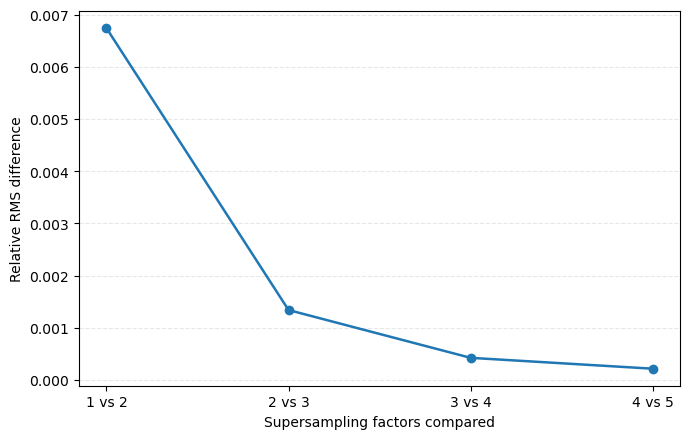

In [7]:

# TEST 4: Numerical convergence

def make_image(supersampling):
    model = sim.image_model_class(kwargs_numerics={"supersampling_factor": supersampling})
    # sim.image_model_class() creates an image-model object using your existing simulation configuration
    # kwargs_numerics is a dictionary containing the numerical settings
    return model.image(kwargs_lens=kwargs_lens, kwargs_source=kwargs_source)

image_1 = make_image(1)
image_2 = make_image(2)
image_3 = make_image(3)
image_4 = make_image(4)
image_5 = make_image(5)

def relative_rms(a, b):
    return np.sqrt(np.mean((a-b)**2)) / np.sqrt(
        np.mean(b**2))

error_12 = relative_rms(image_1, image_2)
error_23 = relative_rms(image_2, image_3)
error_34 = relative_rms(image_3, image_4)
error_45 = relative_rms(image_4, image_5)

print("Relative RMS (1 vs 2):", error_12)
print("Relative RMS (2 vs 3):", error_23)
print("Relative RMS (3 vs 4):", error_34)
print("Relative RMS (4 vs 5):", error_45)

comparisons = ["1 vs 2", "2 vs 3", "3 vs 4", "4 vs 5"]
errors = [error_12, error_23, error_34, error_45]

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(comparisons, errors, marker="o", linewidth=1.8, markersize=6)

ax.set_xlabel("Supersampling factors compared")
ax.set_ylabel("Relative RMS difference")

# ax.set_ylim(0, 0.01)
# ax.set_yticks(np.arange(0, 0.0101, 0.0025))

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("supersampling_convergence.png", dpi=300, bbox_inches="tight")
plt.show()


In [9]:
# TEST: Residual convergence

def make_residual(supersampling):
    model = sim.image_model_class(
        kwargs_numerics={"supersampling_factor": supersampling})

    # Without black hole
    kwargs_baseline = [
        kwargs_lens[0],
        kwargs_lens[1],
        {**kwargs_bh, "theta_E": 0.0}]

    baseline = model.image(
        kwargs_lens=kwargs_baseline,
        kwargs_source=kwargs_source)

    # With black hole
    with_bh = model.image(
        kwargs_lens=kwargs_lens,
        kwargs_source=kwargs_source)

    return with_bh - baseline


residual_3 = make_residual(3)
residual_5 = make_residual(5)
residual_7 = make_residual(7)

print("Relative RMS (3 vs 5):", relative_rms(residual_3, residual_5))
print("Relative RMS (5 vs 7):", relative_rms(residual_5, residual_7))

Relative RMS (3 vs 5): 0.001233743060653454
Relative RMS (5 vs 7): 0.0003446033458662867
